# Privacy Preserving Machine Learning Practical Session 3

Practical Session taken from the Course of Aurélien Bellet

Course page: http://researchers.lille.inria.fr/abellet/teaching/private_machine_learning_course.html

## Goal of the practical session 

In the previous practical sessions, we introduced the essential tools for building privacy-preserving data analysis solutions. In this session, we demonstrate how these tools can be combined to construct more sophisticated privacy-preserving machine learning pipelines. In particular, we focus on the implementation of differentially private empirical risk minimization (DP-ERM), together with standard privacy-preserving first-order optimization methods such as DP-SGD.


## Table of contents
1. [Part 1: Differentially Private ERM](#part0)
    - [Question 1 (Non-private training)](#part0sec1)
    - [Question 2 (Sensitivity)](#part0sec2)
    - [Question 3 (Private training via output perturbation)](#part0sec3)
    - [Bonus Question 4 (Objective perturbation)](#part0sec4)
1. [Part 2: Differentially Private SGD](#part1)
    - [Question 1 (non-private SGD)](#part1sec1)
    - [Question 2 (private SGD)](#part1sec2)
    - [Question 3 (extending the scope of private SGD)](#part1sec3)

In [ ]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ShuffleSplit
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import pandas as pad
from sklearn.preprocessing import LabelBinarizer

# Part 1: Differentially Private ERM <a id="part0"></a>

### Datasets

**You are free to work with any binary classification dataset(s) you like** (you may use more than a single dataset).

You can work on the US Census dataset used in previous practicals, but some of the observations may be more notable on higher dimensional datasets. You can find datasets for instance on [OpenML](https://www.openml.org/), [UCI](https://archive.ics.uci.edu/ml/index.php), [sklearn](https://scikit-learn.org/stable/modules/classes.html?highlight=datasets#module-sklearn.datasets).

The code below loads a version of the Arcene dataset, which aims to distinguish cancer versus healthy patients from mass-spectrometric data.

In [ ]:
X, y = fetch_openml(name="Arcene", version=1, return_X_y=True, as_frame=False)
features_complete = (np.isnan(X).sum(axis=0)) == 0  # features without missing values
X = X[:, features_complete]
scaler = StandardScaler()
X = scaler.fit_transform(X)  # standardize features
n, d = X.shape
print(n, d)

200 10000


### Question 1 (Non-private training) <a id="part0sec1"></a>

We will work with $\ell_2$-regularized logistic regression. For now, let us consider the non-private setting.

1. What is the Lipschitz constant $L$ of the logistic loss for a data point $(x,y)$? Normalize the dataset to ensure that the logistic loss is 1-Lipschitz for any $(x,y)$.
2. For different splits of the dataset into train (80%) and test (20%) sets, plot the accuracy of an $\ell_2$-regularized logistic regression classifier on the test set with respect to the size of the training set. To do this, you can use the `plot_learning_curve` function below, setting its `cv` argument to a `ShuffleSplit` instance (see [sklearn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ShuffleSplit.html)).

### Answer
For one data point $(x,y)$, the logistic loss is
$$
\ell(\theta;(x,y)) = \log(1+\exp(-y\theta^\top x)).
$$

Its gradient with respect to $\theta$ is
$$
\nabla_\theta \ell(\theta;(x,y)) = -\frac{yx}{1+\exp(y\theta^\top x)}.
$$

Hence,
$$
\|\nabla_\theta \ell(\theta;(x,y))\|_2 \le \|x\|_2,
$$
so the Lipschitz constant is
$$
L = \|x\|_2.
$$

Therefore, to make the logistic loss 1-Lipschitz for every $(x,y)$, we normalize the dataset so that each sample satisfies
$$
\|x\|_2 \le 1.
$$

In practice, we can standardize the features first and then apply $\ell_2$ normalization to each sample.


In [ ]:
if sp.sparse.issparse(X):
    scaler = StandardScaler(with_mean=False)
else:
    scaler = StandardScaler()

normalizer = Normalizer()
X = normalizer.transform(scaler.fit_transform(X))

In [ ]:
def learning_curve(estimator, X, y, cv, train_sizes=np.linspace(0.1, 1.0, 5)):
    """Learning curve.

    Determines cross-validated training and test scores for different training
    set sizes.

    A cross-validation generator splits the whole dataset k times in training
    and test data. Subsets of the training set with varying sizes will be used
    to train the estimator and a score for each training subset size and the
    test set will be computed. Afterwards, the scores will be averaged over
    all k runs for each training subset size.

    Parameters
    ----------
    estimator : object type that implements the "fit" and "predict" methods
        An object of that type which is cloned for each validation.

    X : array-like, shape (n_samples, n_features)
        Training vector, where n_samples is the number of samples and
        n_features is the number of features.

    y : array-like, shape (n_samples) or (n_samples, n_features), optional
        Target relative to X for classification or regression;
        None for unsupervised learning.

    cv : cross-validation generator
        Cross-validation object, see sklearn.model_selection module
        for the list of possible objects

    train_sizes : array-like, shape (n_ticks,), dtype float
        Relative numbers of training examples that will be used to
        generate the learning curve. If the dtype is float, it is regarded as a
        fraction of the maximum size of the training set (that is determined
        by the selected validation method), i.e. it has to be within (0, 1].
        (default: np.linspace(0.1, 1.0, 5))

    Returns
    -------
    train_sizes_abs : array, shape (n_unique_ticks,), dtype int
        Numbers of training examples that has been used to generate the
        learning curve. Note that the number of ticks might be less
        than n_ticks because duplicate entries will be removed.

    train_scores : array, shape (n_ticks, n_cv_folds)
        Scores on training sets.

    test_scores : array, shape (n_ticks, n_cv_folds)
        Scores on test set.
    """

    n_max_training_samples = len(
        list(cv.split(X))[0][0]
    )  # computing the size of the maximum training sample (if we take all)
    train_sizes_abs = (train_sizes * n_max_training_samples).astype(
        int
    )  # computing the size of of each sub-training samples according to train sizes

    train_scores = []
    test_scores = []

    for train, test in cv.split(X):
        X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]
        this_train_scores = []
        this_test_scores = []
        for n in train_sizes_abs:
            estimator.fit(X_train[:n], y_train[:n])
            this_train_scores.append(estimator.score(X_train[:n], y_train[:n]))
            this_test_scores.append(estimator.score(X_test, y_test))

        train_scores.append(this_train_scores)
        test_scores.append(this_test_scores)

    return train_sizes_abs, np.transpose(train_scores), np.transpose(test_scores)


def plot_learning_curve(
    estimator, X, y, title="", ylim=None, cv=None, train_sizes=np.linspace(0.1, 1.0, 5)
):
    """Generate a simple plot of the test (or validation) and training learning curve.

    Parameters
    ----------
    estimator : object type that implements the "fit" and "predict" methods
        An object of that type which is cloned for each validation.

    title : string
        Title for the chart.

    X : array-like, shape (n_samples, n_features)
        Training vector, where n_samples is the number of samples and
        n_features is the number of features.

    y : array-like, shape (n_samples) or (n_samples, n_features), optional
        Target relative to X for classification or regression;
        None for unsupervised learning.

    ylim : tuple, shape (ymin, ymax), optional
        Defines minimum and maximum yvalues plotted.

    cv : integer, cross-validation generator, optional
        If an integer is passed, it is the number of folds (defaults to 3).
        Specific cross-validation objects can be passed, see
        sklearn.cross_validation module for the list of possible objects

    n_jobs : integer, optional
        Number of jobs to run in parallel (default 1).
    """
    plt.figure()
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples")
    plt.ylabel("Score")
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, train_sizes=train_sizes
    )
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(
        train_sizes,
        train_scores_mean - train_scores_std,
        train_scores_mean + train_scores_std,
        alpha=0.1,
        color="r",
    )
    plt.fill_between(
        train_sizes,
        test_scores_mean - test_scores_std,
        test_scores_mean + test_scores_std,
        alpha=0.1,
        color="g",
    )
    plt.plot(train_sizes, train_scores_mean, "o-", color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, "o-", color="g", label="Test score")

    plt.legend(loc="best")

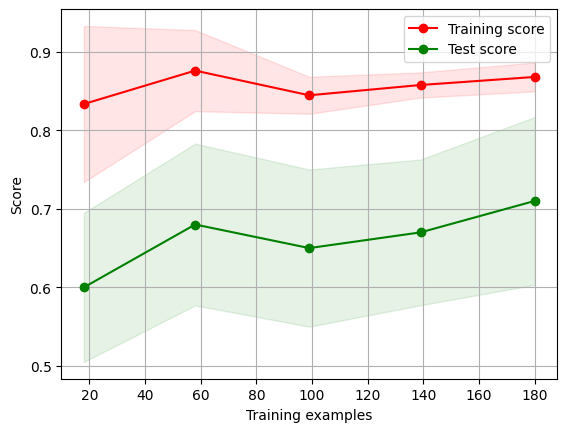

In [ ]:
plot_learning_curve(LogisticRegression(), X, y, cv=ShuffleSplit(5))

### Question 2 (Sensitivity) <a id="part0sec2"></a>

Recall the $\ell_2$ regularized logistic regression solves the following problem:
$$\arg\min_{\theta\in\mathbb{R}^p} \frac{1}{n}\sum_{i=1}^n \log(1+e^{-y
(\theta^\top x)}) + \lambda\|\theta\|_2^2$$

1. What is the theoretical upper-bound on the $\ell_2$-sensitivity of the above formulation, based on the result seen in the lecture?
2. We would like to see how large the sensitivity is in practice when we train a logistic regression classifier on two neighboring datasets. Let `n_eval` be the training set size and `n_runs` the number of times we would like to repeat the experiment. For each of the `n_runs` experiments, you should randomly generate a pair of neighboring datasets $D,D'$ of size `n_eval` which differ on a single data point, train logistic regression on $D$ and $D'$, and compute the sensitivity you observe empirically. Implement this procedure as a function.
3. For `n_eval=100`, `n_runs=100` and a value $\lambda$ of your choice, use the function you implemented to compare the "empirical sensitivity" you observe to the theoretical bound. Explain any discrepancy between the two. **Warning**: scikit-learn solves the logistic regression problem in a slighly different form, see the [documentation](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression). You should make sure that you appropriately convert the value $\lambda$ in the optimization problem above into a value for the parameter `C` of the implementation so that both problems are equivalent.

### Answer
Since each example is normalized so that $\|x\|_2 \le 1$, the logistic loss is 1-Lipschitz.

For
$$
\min_\theta \frac{1}{n}\sum_{i=1}^n \log(1+e^{-y_i \theta^\top x_i}) + \lambda \|\theta\|_2^2,
$$
the regularizer is $2\lambda$-strongly convex, so the theoretical $\ell_2$-sensitivity bound is
$$
\Delta_2 \le \frac{1}{\lambda n}.
$$

In scikit-learn, the objective is written in an equivalent form with parameter $C$, and matching the two formulations gives
$$
C = \frac{1}{2\lambda n}.
$$

For $n=100$ and the chosen value of $\lambda$, we compare this theoretical upper bound with the empirical sensitivity obtained by training on random neighboring datasets. The empirical sensitivities are usually much smaller than the theoretical bound because the latter is a worst-case guarantee, while the experiment only considers random pairs of neighboring datasets. Small differences may also come from numerical optimization.


Mean empirical sensitivity:   0.0394
Max empirical sensitivity:    0.0569
Theoretical upper bound:      0.1000


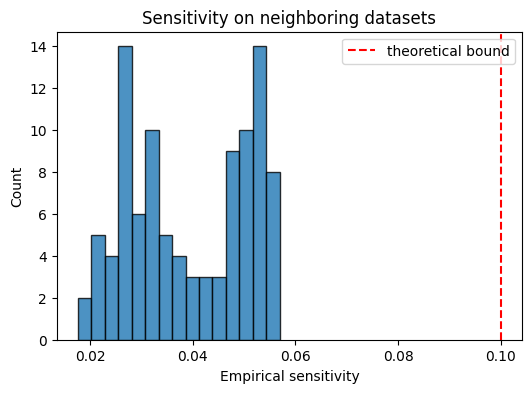

In [ ]:
from sklearn.exceptions import ConvergenceWarning
import warnings

# Ensure the 1-Lipschitz assumption from Question 1.
X_q2 = Normalizer().fit_transform(X)
classes = np.unique(y)
y_q2 = (y == classes[1]).astype(int)


def sklearn_C_from_lambda(lamb, n_samples):
    # sklearn uses mean(loss) + ||w||^2 / (2 * C * n)
    # so matching mean(loss) + lamb * ||w||^2 gives C = 1 / (2 * lamb * n)
    return 1.0 / (2.0 * lamb * n_samples)


def fit_logreg(X_train, y_train, lamb):
    model = LogisticRegression(
        C=sklearn_C_from_lambda(lamb, len(X_train)),
        penalty="l2",
        solver="lbfgs",
        fit_intercept=True,
        max_iter=5000,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X_train, y_train)
    return model


def parameter_vector(model):
    return np.concatenate([model.coef_.ravel(), model.intercept_.ravel()])


def empirical_sensitivity(X, y, n_eval, n_runs, lamb, random_state=0):
    rng = np.random.default_rng(random_state)
    n = len(X)
    if n_eval >= n:
        raise ValueError("n_eval must be smaller than the dataset size.")

    sensitivities = []
    for _ in range(n_runs):
        for _ in range(1000):
            idx = rng.choice(n, size=n_eval + 1, replace=False)
            idx_D = idx[:n_eval]
            idx_D_prime = np.concatenate([idx[: n_eval - 1], idx[-1:]])

            if len(np.unique(y[idx_D])) == 2 and len(np.unique(y[idx_D_prime])) == 2:
                break
        else:
            raise RuntimeError("Could not sample two valid neighboring datasets.")

        model_D = fit_logreg(X[idx_D], y[idx_D], lamb)
        model_D_prime = fit_logreg(X[idx_D_prime], y[idx_D_prime], lamb)
        sens = np.linalg.norm(parameter_vector(model_D) - parameter_vector(model_D_prime))
        sensitivities.append(sens)

    return np.array(sensitivities)


lamb = 0.1
n_eval = 100
n_runs = 100

theoretical_bound = 1.0 / (lamb * n_eval)
sensitivities = empirical_sensitivity(X_q2, y_q2, n_eval=n_eval, n_runs=n_runs, lamb=lamb)

print(f"Mean empirical sensitivity:   {sensitivities.mean():.4f}")
print(f"Max empirical sensitivity:    {sensitivities.max():.4f}")
print(f"Theoretical upper bound:      {theoretical_bound:.4f}")

plt.figure(figsize=(6, 4))
plt.hist(sensitivities, bins=15, alpha=0.8, edgecolor="black")
plt.axvline(theoretical_bound, color="red", linestyle="--", label="theoretical bound")
plt.xlabel("Empirical sensitivity")
plt.ylabel("Count")
plt.title("Sensitivity on neighboring datasets")
plt.legend()
plt.show()

### Question 3 (Private training via output perturbation) <a id="part0sec3"></a>

Assume that you hold the private dataset and you would like to publicly release a logistic regression classifier trained on private dataset in a differentially private manner. We will do this with the DP-ERM via output perturbation approach seen in the lecture.

1. Do you think it is safe to use an empirical estimate of the sensitivity (e.g., as computed in Question 2) instead of a theoretical upper-bound to calibrate the noise? Justify your answer.
2. Implement the DP-ERM via output perturbation approach. The function should take as input a (private) training dataset, a value of regularization parameter $\lambda$, and privacy parameters $\epsilon$ and $\delta$, and return a model trained on the private dataset in an $(\epsilon,\delta)$-DP manner.
3. Experiment with your DP-ERM implementation for different training set size, regularization parameter and privacy parameter $\epsilon$ (you can set $\delta$ to a fixed value by following the recommendation seen in the second lecture or in previous practicals). Compare the test accuracy of the resulting model to the non-private case. Discuss the trade-offs you obtain.

### Answer 
1.No, it is not safe to use an empirical estimate of the sensitivity to calibrate the noise. Differential privacy requires a worst-case upper bound that must hold for all neighboring datasets. An empirical estimate is computed from a limited set of random experiments and may underestimate the true sensitivity, which could lead to insufficient noise and break the privacy guarantee.
2.We implemented DP-ERM with output perturbation for $\ell_2$-regularized logistic regression. The method first trains the non-private model, then adds Gaussian noise to the parameter vector. Using the theoretical sensitivity bound
$$
\Delta_2 \le \frac{1}{\lambda n},
$$
the noise is calibrated as
$$
\sigma = \frac{\Delta_2 \sqrt{2\log(1.25/\delta)}}{\epsilon},
$$
which gives an $(\epsilon,\delta)$-DP mechanism.
3.The experiments show the expected privacy-utility trade-off. In general, the private model is less accurate than the non-private model, especially for smaller values of $\epsilon$. As $\epsilon$ increases from $0.5$ to $2.0$, the private accuracy improves because less noise is added. We also observe that larger training sets can help, although the trend is not perfectly monotonic because the dataset is small and the experiments remain noisy. In some cases, the private model is close to the non-private one, and it can even slightly outperform it due to randomness, but overall the non-private model remains more stable. These results are consistent with the fact that stronger privacy requires more noise and therefore typically reduces utility.


delta = 3.91e-05
Example run
Non-private accuracy: 0.5500
Private accuracy:     0.5500
    n_train  lambda  epsilon  non_private_acc  private_acc
0        80    0.05      0.5           0.5850       0.5225
1        80    0.05      1.0           0.5875       0.5200
2        80    0.05      2.0           0.6000       0.5425
3        80    0.10      0.5           0.5775       0.5350
4        80    0.10      1.0           0.5925       0.5450
5        80    0.10      2.0           0.5575       0.5450
6        80    0.20      0.5           0.5575       0.5275
7        80    0.20      1.0           0.5525       0.5400
8        80    0.20      2.0           0.5575       0.5625
9       120    0.05      0.5           0.5825       0.5400
10      120    0.05      1.0           0.6050       0.5575
11      120    0.05      2.0           0.5750       0.5750
12      120    0.10      0.5           0.5650       0.5575
13      120    0.10      1.0           0.5575       0.5550
14      120    0.10      2.0

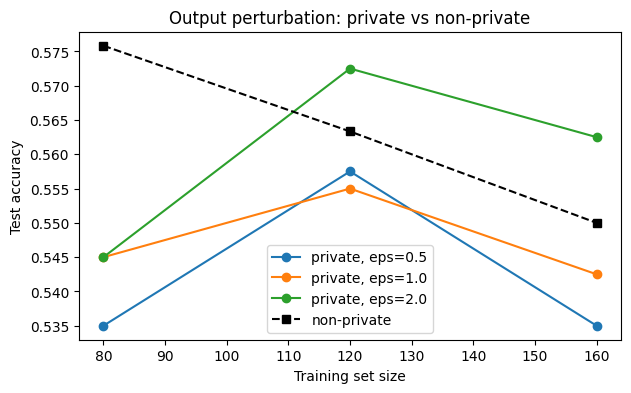

In [60]:
from dataclasses import dataclass
from sklearn.model_selection import train_test_split


@dataclass
class PrivateLogisticModel:
    coef_: np.ndarray
    intercept_: np.ndarray

    def decision_function(self, X):
        return X @ self.coef_.ravel() + self.intercept_[0]

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

    def score(self, X, y):
        return np.mean(self.predict(X) == y)


def gaussian_noise_scale(sensitivity, epsilon, delta):
    return sensitivity * np.sqrt(2 * np.log(1.25 / delta)) / epsilon


def dp_logistic_output_perturbation(X_train, y_train, lamb, epsilon, delta, random_state=None):
    n_train = len(X_train)
    base_model = fit_logreg(X_train, y_train, lamb)
    theta_hat = parameter_vector(base_model)

    sensitivity = 1.0 / (lamb * n_train)
    sigma = gaussian_noise_scale(sensitivity, epsilon, delta)
    rng = np.random.default_rng(random_state)
    theta_private = theta_hat + rng.normal(0, sigma, size=theta_hat.shape)

    return PrivateLogisticModel(
        coef_=theta_private[:-1].reshape(1, -1),
        intercept_=theta_private[-1:].copy(),
    )


X_q3 = X_q2
y_q3 = y_q2
X_train, X_test, y_train, y_test = train_test_split(
    X_q3, y_q3, train_size=0.8, random_state=42, stratify=y_q3
)
delta = 1 / (len(X_train) ** 2)

print(f"delta = {delta:.2e}")

# 2. Example of private training
lamb = 0.1
epsilon = 1.0
non_private_model = fit_logreg(X_train, y_train, lamb)
private_model = dp_logistic_output_perturbation(
    X_train, y_train, lamb=lamb, epsilon=epsilon, delta=delta, random_state=0
)

print("Example run")
print(f"Non-private accuracy: {non_private_model.score(X_test, y_test):.4f}")
print(f"Private accuracy:     {private_model.score(X_test, y_test):.4f}")

# 3. Compare train size, lambda and epsilon
train_sizes = [80, 120, 160]
lambdas = [0.05, 0.1, 0.2]
epsilons = [0.5, 1.0, 2.0]
n_repeats = 10
rng = np.random.default_rng(0)

results = []
for n_train_sub in train_sizes:
    for lamb in lambdas:
        for epsilon in epsilons:
            private_scores = []
            non_private_scores = []

            for rep in range(n_repeats):
                for _ in range(1000):
                    idx = rng.choice(len(X_train), size=n_train_sub, replace=False)
                    if len(np.unique(y_train[idx])) == 2:
                        break
                X_sub = X_train[idx]
                y_sub = y_train[idx]
                delta_sub = 1 / (n_train_sub ** 2)

                non_private_model = fit_logreg(X_sub, y_sub, lamb)
                private_model = dp_logistic_output_perturbation(
                    X_sub,
                    y_sub,
                    lamb=lamb,
                    epsilon=epsilon,
                    delta=delta_sub,
                    random_state=rep,
                )

                non_private_scores.append(non_private_model.score(X_test, y_test))
                private_scores.append(private_model.score(X_test, y_test))

            results.append(
                {
                    "n_train": n_train_sub,
                    "lambda": lamb,
                    "epsilon": epsilon,
                    "non_private_acc": np.mean(non_private_scores),
                    "private_acc": np.mean(private_scores),
                }
            )

results_df = pad.DataFrame(results)
print(results_df.round(4))

plt.figure(figsize=(7, 4))
for epsilon in epsilons:
    df_eps = results_df[(results_df["epsilon"] == epsilon) & (results_df["lambda"] == 0.1)]
    grouped = df_eps.groupby("n_train")[["non_private_acc", "private_acc"]].mean().reset_index()
    plt.plot(grouped["n_train"], grouped["private_acc"], marker="o", label=f"private, eps={epsilon}")

baseline = results_df[results_df["lambda"] == 0.1].groupby("n_train")["non_private_acc"].mean().reset_index()
plt.plot(baseline["n_train"], baseline["non_private_acc"], marker="s", linestyle="--", color="black", label="non-private")
plt.xlabel("Training set size")
plt.ylabel("Test accuracy")
plt.title("Output perturbation: private vs non-private")
plt.legend()
plt.show()

### Bonus Question 4 (Objective perturbation) <a id="part0sec4"></a>

Beyond output perturbation, the work of [Chaudhuri et al. (2011)](https://www.jmlr.org/papers/volume12/chaudhuri11a/chaudhuri11a.pdf) introduces a DP-ERM algorithm based on *objective perturbation*. Implement this algorithm for $\ell_2$-regularized regression and compare the results with those of output perturbation.

To optimize the perturbed objective, you may use a solver from `scipy.optimize.minimize` (such as L-BFGS, which is used by default by scikit-learn to fit logistic regression). You will need to implement a function that computes the objective value and the gradient at a given point: for this, you can adapt [the one used in scikit-learn for the non-perturbed objective](https://github.com/scikit-learn/scikit-learn/blob/0fb307bf39bbdacd6ed713c00724f8f871d60370/sklearn/linear_model/_logistic.py#L84).

# Part 2: Differentially Private SGD  <a id="part1"></a>

**You are free to work with any binary classification dataset(s) you like** (you may use more than a single dataset). It is of course possible to work with the US Census dataset used in previous practicals, but you can find other datasets for instance on [OpenML](https://www.openml.org/), [UCI](https://archive.ics.uci.edu/ml/index.php), [sklearn](https://scikit-learn.org/stable/modules/classes.html?highlight=datasets#module-sklearn.datasets).

Good candidate datasets should have rather small dimension compared to the number of data points. Examples include US Census in one-hot encoded version (`name='a9a', version=1`), houses (`name='houses', version=2`) and electricity (`name='electricity', version=1`).

The code below loads the US Census dataset in one-hot encoded version.

In [ ]:
X, y = fetch_openml(name="a9a", version=1, return_X_y=True, as_frame=False)
n, d = X.shape

# convert labels to -1, 1
c = np.unique(y)
y[y == c[0]] = -1
y[y == c[1]] = 1
y = y.astype(float)

print(n, d)

48842 123


We first standardize features, then normalize each point to have unit norm.

In [ ]:
if sp.sparse.issparse(X):
    scaler = StandardScaler(with_mean=False)
else:
    scaler = StandardScaler()
X_unnorm_sgd = scaler.fit_transform(X)
normalizer = Normalizer()
X = normalizer.transform(X_unnorm_sgd)

We now split the dataset into a train and a test set. Feel free to adapt the size of the training set to your dataset.

In [ ]:
X_train_sgd, X_test_sgd, y_train_sgd, y_test_sgd = train_test_split(
    X, y, train_size=0.80, random_state=42, stratify=y
)
print(X_train_sgd.shape, y_train_sgd.shape, X_test_sgd.shape, y_test_sgd.shape)
n_train = X_train_sgd.shape[0]

(39073, 123) (39073,) (9769, 123) (9769,)


## Question 1 (non-private SGD) <a id="part1sec1"></a>

In this first question, we will implement our own simple version of SGD. This will be convenient when we will implement a differentially private version in Question 2.

Below, you are given several pieces of code:
1. A function `sgd` which implements SGD: it is meant to be generic in the sense that it takes as input a function `obj_and_grad` which computes the value and the gradient of the desired objective function. **This function has missing parts that you need to complete**.
2. A function `my_logistic_obj_and_grad` (adapted from [the version from sklearn](https://github.com/scikit-learn/scikit-learn/blob/0fb307bf39bbdacd6ed713c00724f8f871d60370/sklearn/linear_model/_logistic.py#L84)) which computes the value and gradient of the logistic regression problem. You do not need to modify this function.
3. A class `MySGDLogisticRegression` which defines a sklearn estimator for logistic regression, where the model is fit using SGD using the previous two functions. You do not need to modify this function.

Spend a bit of time to get familiar with the code provided, then complete the missing bits in the `sgd` function. Make sure it works by trying it on the binary classification dataset that you previously loaded.

In [ ]:
def sgd(
    X,
    y,
    gamma,
    n_iter,
    obj_and_grad,
    theta_init,
    n_batch=1,
    freq_obj_eval=10,
    n_obj_eval=1000,
    random_state=None,
):
    """Stochastic Gradient Descent (SGD) algorithm

    Parameters
    ----------
    X : array, shape (n, d)
        The data
    y : array, shape (n,)
        Binary labels (-1, 1).
    gamma : float | callable
        The step size. Can be a constant float or a function
        that allows to have a variable step size
    n_iter : int
        The number of iterations
    obj_and_grad : callable
        A function which takes as a vector of shape (p,), a dataset of shape (n_batch, d)
        and a label vector of shape (n_batch,), and returns the objective value and gradient.
    theta_init : array, shape (p,)
        The initial value for the model parameters
    n_batch : int
        Size of the mini-batch to use at each iteration of SGD.
    freq_obj_eval : int
        Specifies the frequency (in number of iterations) at which we compute the objective
    n_obj_eval : int
        The number of points on which we evaluate the objective
    random_state : int
        Random seed to make the algorithm deterministic


    Returns
    -------
    theta : array, shape=(p,)
        The final value of the model parameters
    obj_list : list of length (n_iter / freq_obj_eval)
        A list containing the value of the objective function computed every freq_obj_eval iterations
    """

    rng = np.random.RandomState(random_state)
    n, d = X.shape
    p = theta_init.shape[0]

    theta = theta_init.copy()

    # if a constant step size was provided, we turn it into a constant function
    if not callable(gamma):

        def gamma_func(t):
            return gamma

    else:
        gamma_func = gamma

    # list to record the evolution of the objective (for plotting)
    obj_list = []
    # we draw a fixed subset of points to monitor the objective
    idx_eval = rng.randint(0, n, n_obj_eval)

    for t in range(n_iter):
        if t % freq_obj_eval == 0:
            # evaluate objective
            obj, _ = obj_and_grad(theta, X[idx_eval, :], y[idx_eval])
            obj_list.append(obj)

        idx_batch = rng.randint(0, n, n_batch)
        _, grad = obj_and_grad(theta, X[idx_batch, :], y[idx_batch])
        theta -= gamma_func(t) * grad

    return theta, obj_list

In [ ]:
from sklearn.linear_model._base import (
    LinearClassifierMixin,
    SparseCoefMixin,
    BaseEstimator,
)
from sklearn.utils.extmath import safe_sparse_dot
from scipy.special import expit
from sklearn.utils.validation import check_X_y


def _intercept_dot(w, X, y):
    """Computes y * np.dot(X, w)."""
    c = 0.0
    if w.size == X.shape[1] + 1:
        c = w[-1]
        w = w[:-1]
    z = X.dot(w)
    if c != 0.0:
        z = z + c
    yz = y * z
    return w, c, yz


def my_logistic_obj_and_grad(theta, X, y, lamb):
    """Computes the value and gradient of the objective function of logistic regression defined as:
    min (1/n) \sum_i log_loss(theta;X[i,:],y[i]) + (lamb / 2) \|w\|^2,
    where theta = w (if no intercept), or theta = [w b] (if intercept)

    Parameters
    ----------
    theta_init : array, shape (d,) or (d+1,)
        The initial value for the model parameters. When an intercept is used, it corresponds to the last entry
    X : array, shape (n, d)
        The data
    y : array, shape (n,)
        Binary labels (-1, 1)
    lamb : float
        The L2 regularization parameter


    Returns
    -------
    obj : float
        The value of the objective function
    grad : array, shape (d,) or (d+1,)
        The gradient of the objective function
    """
    n_samples, n_features = X.shape
    grad = np.empty_like(theta)

    w, c, yz = _intercept_dot(theta, X, y)

    z = expit(yz)
    obj = np.mean(np.logaddexp(0, -yz)) + .5 * lamb * np.dot(w, w)

    
    z0 = (z - 1) * y

    grad[:n_features] = safe_sparse_dot(X.T, z0) / n_samples + lamb * w

    # Case where we fit the intercept
    if grad.shape[0] > n_features:
        grad[-1] = z0.sum() / n_samples
    return obj, grad


class MySGDLogisticRegression(BaseEstimator, LinearClassifierMixin, SparseCoefMixin):
    """Our own sklearn estimator for logistic regression defined as:
    min (1/n) \sum_i log_loss(theta;X[i,:],y[i]) + (lamb / 2) \|w\|^2,
    where theta = [w b]

    Parameters
    ----------
    gamma : float | callable
        The step size. Can be a constant float or a function
        that allows to have a variable step size
    n_iter : int
        The number of iterations
    lamb : float
        The L2 regularization parameter
    n_batch : int
        Size of the mini-batch to use at each iteration of SGD.
    freq_obj_eval : int
        Specifies the frequency (in number of iterations) at which we compute the objective
    n_obj_eval : int
        The number of points on which we evaluate the objectuve
    random_state : int
        Random seed to make the algorithm deterministic

    Attributes
    ----------
    coef_ : (p,)
        The weights of the logistic regression model.
    intercept_ : (1,)
        The intercept term of the logistic regression model.
    obj_list_: list of length (n_iter / freq_obj_eval)
        A list containing the value of the objective function computed every freq_loss_eval iterations
    """

    def __init__(
        self,
        gamma,
        n_iter,
        lamb=0,
        n_batch=1,
        freq_obj_eval=10,
        n_obj_eval=1000,
        random_state=None,
    ):
        self.gamma = gamma
        self.n_iter = n_iter
        self.lamb = lamb
        self.n_batch = n_batch
        self.freq_obj_eval = freq_obj_eval
        self.n_obj_eval = n_obj_eval
        self.random_state = random_state

    def fit(self, X, y):

        # WARNING: assumes labels are -1, 1
        X, y = check_X_y(
            X, y, accept_sparse="csr", dtype=[np.float64, np.float32], order="C"
        )
        self.classes_ = np.unique(y)

        p = X.shape[1]
        theta_init = np.zeros(p + 1)  # initialize parameters to zero
        # define the function for value and gradient needed by SGD
        obj_grad = lambda theta, X, y: my_logistic_obj_and_grad(
            theta, X, y, lamb=self.lamb
        )
        theta, obj_list = sgd(
            X,
            y,
            self.gamma,
            self.n_iter,
            obj_grad,
            theta_init,
            self.n_batch,
            self.freq_obj_eval,
            self.n_obj_eval,
            self.random_state,
        )

        # save the learned model into the appropriate quantities used by sklearn
        self.intercept_ = np.expand_dims(theta[-1], axis=0)
        self.coef_ = np.expand_dims(theta[:-1], axis=0)

        # also save list of objective values during optimization for plotting
        self.obj_list_ = obj_list

        return self

Test accuracy 0.8307912785341386


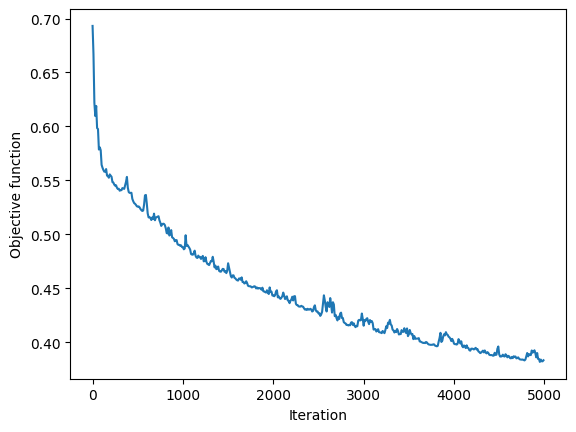

In [ ]:
lamb = 0
n_iter = 5000
n_batch = 1
gamma = 0.05

mlr = MySGDLogisticRegression(gamma, n_iter, lamb, n_batch=n_batch, random_state=None)
mlr.fit(X_train_sgd, y_train_sgd)
print("Test accuracy", mlr.score(X_test_sgd, y_test_sgd))

obj_list = mlr.obj_list_
iter_list = np.arange(len(obj_list)) * mlr.freq_obj_eval
plt.plot(iter_list, obj_list)
plt.xlabel("Iteration")
plt.ylabel("Objective function")
plt.show()

## Question 2 (private SGD) <a id="part1sec2"></a>

We will now implement and experiment with DP-SGD:
1. Following the model of the function `sgd`, implement a new function `private_sgd` which implements DP-SGD **with mini-batch size of 1 and no regularization**. It can take as input the desired value of $\epsilon$ and $\delta$ for the $(\epsilon,\delta)$-DP, or alternatively the standard deviation of the Gaussian noise to add at each iteration. Note: you do not need to make the objective plotting part private (this is only for monitoring).
2. Following the model of the class `MySGDLogisticRegression`, implement a new class `MyPrivateSGDLogisticRegression` which implements differentially private logistic regression trained using your DP-SGD implementation above.

In [ ]:
def dp_sgd_noise_std(epsilon, delta, n_iter, sensitivity=2 * np.sqrt(2.0)):
    """Calibrate Gaussian noise by basic composition over SGD iterations."""
    eps_per_iter = epsilon / n_iter
    delta_per_iter = delta / n_iter
    return sensitivity * np.sqrt(2 * np.log(1.25 / delta_per_iter)) / eps_per_iter


def private_sgd(
    X,
    y,
    gamma,
    n_iter,
    obj_and_grad,
    theta_init,
    epsilon=None,
    delta=None,
    noise_std=None,
    freq_obj_eval=10,
    n_obj_eval=1000,
    random_state=None,
):
    rng = np.random.RandomState(random_state)
    n, d = X.shape
    theta = theta_init.copy()

    if not callable(gamma):
        def gamma_func(t):
            return gamma
    else:
        gamma_func = gamma

    if noise_std is None:
        if epsilon is None or delta is None:
            raise ValueError("Provide either noise_std or both epsilon and delta.")
        noise_std = dp_sgd_noise_std(epsilon, delta, n_iter)

    obj_list = []
    idx_eval = rng.randint(0, n, n_obj_eval)

    for t in range(n_iter):
        if t % freq_obj_eval == 0:
            obj, _ = obj_and_grad(theta, X[idx_eval, :], y[idx_eval])
            obj_list.append(obj)

        idx = rng.randint(0, n)
        _, grad = obj_and_grad(theta, X[idx:idx+1, :], y[idx:idx+1])
        noise = rng.normal(0, noise_std, size=theta.shape)
        theta -= gamma_func(t) * (grad + noise)

    return theta, obj_list


Private test accuracy 0.7567816562595967


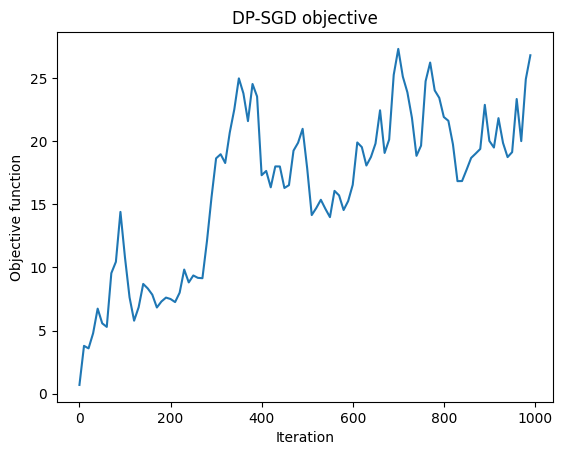

In [53]:
class MyPrivateSGDLogisticRegression(BaseEstimator, LinearClassifierMixin, SparseCoefMixin):
    def __init__(
        self,
        gamma,
        n_iter,
        epsilon=None,
        delta=None,
        noise_std=None,
        freq_obj_eval=10,
        n_obj_eval=1000,
        random_state=None,
    ):
        self.gamma = gamma
        self.n_iter = n_iter
        self.epsilon = epsilon
        self.delta = delta
        self.noise_std = noise_std
        self.freq_obj_eval = freq_obj_eval
        self.n_obj_eval = n_obj_eval
        self.random_state = random_state

    def fit(self, X, y):
        X, y = check_X_y(
            X, y, accept_sparse="csr", dtype=[np.float64, np.float32], order="C"
        )
        self.classes_ = np.unique(y)

        p = X.shape[1]
        theta_init = np.zeros(p + 1)
        obj_grad = lambda theta, X, y: my_logistic_obj_and_grad(theta, X, y, lamb=0)

        theta, obj_list = private_sgd(
            X,
            y,
            self.gamma,
            self.n_iter,
            obj_grad,
            theta_init,
            epsilon=self.epsilon,
            delta=self.delta,
            noise_std=self.noise_std,
            freq_obj_eval=self.freq_obj_eval,
            n_obj_eval=self.n_obj_eval,
            random_state=self.random_state,
        )

        self.intercept_ = np.expand_dims(theta[-1], axis=0)
        self.coef_ = np.expand_dims(theta[:-1], axis=0)
        self.obj_list_ = obj_list
        return self


epsilon = 3.0
delta = 1 / (X_train_sgd.shape[0] ** 2)
n_iter = 1000
gamma = 0.0005

private_mlr = MyPrivateSGDLogisticRegression(
    gamma=gamma,
    n_iter=n_iter,
    epsilon=epsilon,
    delta=delta,
    random_state=0,
)
private_mlr.fit(X_train_sgd, y_train_sgd)
print("Private test accuracy", private_mlr.score(X_test_sgd, y_test_sgd))


obj_list = private_mlr.obj_list_
iter_list = np.arange(len(obj_list)) * private_mlr.freq_obj_eval
plt.plot(iter_list, obj_list)
plt.xlabel("Iteration")
plt.ylabel("Objective function")
plt.title("DP-SGD objective")
plt.show()


## Question 3 (extending the scope of private SGD) <a id="part1sec3"></a>

Let us consider the following extensions, which were briefly discussed in the lecture:
1. *Mini-batch*: What is the sensitivity of a stochastic gradient when it is evaluated on a mini-batch of $b$ data points (parameter `n_batch` in the code above) ? Adapt your code if needed.
2. *Gradient clipping*: If the loss function $L$ is not Lipschitz, or when the Lipschitz constant is difficult to bound, the idea of gradient clipping consists in rescaling each individual gradient that have a norm larger than some constant $C$ to have norm equal to $C$:
$$\text{clip}(\nabla L(\theta;x,y), C) = \min\Big(1,\frac{C}{\|\nabla L(\theta;x,y)\|_2}\Big)\nabla L(\theta;x,y)$$

Explain how this allows to bound the gradient sensitivity without any assumption on the Lipschitzness of the loss. Implement this variant in a function `private_sgd_with_clipping` and explore how to choose the value of $C$ for logistic regression on the *unnormalized* version of your dataset.

In [54]:
def private_sgd_with_clipping(
    X,
    y,
    gamma,
    n_iter,
    obj_and_grad,
    theta_init,
    C,
    n_batch=1,
    epsilon=None,
    delta=None,
    noise_std=None,
    freq_obj_eval=10,
    n_obj_eval=1000,
    random_state=None,
):
    rng = np.random.RandomState(random_state)
    n, d = X.shape
    theta = theta_init.copy()

    if not callable(gamma):
        def gamma_func(t):
            return gamma
    else:
        gamma_func = gamma

    # After clipping each per-example gradient to norm C, the sensitivity of
    # the average mini-batch gradient is at most 2C / n_batch.
    sensitivity = 2.0 * C / n_batch
    if noise_std is None:
        if epsilon is None or delta is None:
            raise ValueError("Provide either noise_std or both epsilon and delta.")
        noise_std = dp_sgd_noise_std(epsilon, delta, n_iter, sensitivity=sensitivity)

    obj_list = []
    idx_eval = rng.randint(0, n, min(n_obj_eval, n))

    for t in range(n_iter):
        if t % freq_obj_eval == 0:
            obj, _ = obj_and_grad(theta, X[idx_eval, :], y[idx_eval])
            obj_list.append(obj)

        idx_batch = rng.randint(0, n, n_batch)
        clipped_grads = []
        for idx in idx_batch:
            _, grad_i = obj_and_grad(theta, X[idx:idx+1, :], y[idx:idx+1])
            grad_norm = np.linalg.norm(grad_i)
            clip_factor = min(1.0, C / max(grad_norm, 1e-12))
            clipped_grads.append(clip_factor * grad_i)

        avg_grad = np.mean(clipped_grads, axis=0)
        noise = rng.normal(0, noise_std, size=theta.shape)
        theta -= gamma_func(t) * (avg_grad + noise)

    return theta, obj_list


print("Mini-batch sensitivity for normalized logistic regression:")
for b in [1, 4, 16, 64]:
    print(f"b = {b:2d} -> sensitivity <= {2 * np.sqrt(2.0) / b:.4f}")


Mini-batch sensitivity for normalized logistic regression:
b =  1 -> sensitivity <= 2.8284
b =  4 -> sensitivity <= 0.7071
b = 16 -> sensitivity <= 0.1768
b = 64 -> sensitivity <= 0.0442


     C  test_accuracy_mean  test_accuracy_std  final_objective_mean
0  0.1              0.6109             0.0868                0.6687
1  0.5              0.6106             0.0868                0.8246
2  1.0              0.6017             0.0853                1.2401
3  2.0              0.5785             0.0892                2.2541
4  5.0              0.5585             0.0957                5.5861


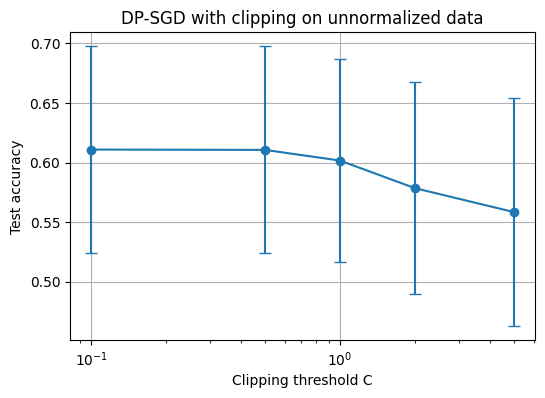

In [59]:
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X_unnorm_sgd, y, train_size=0.8, random_state=42, stratify=y
)

gamma = 0.001
n_iter = 500
n_batch = 32
epsilon = 20.0
delta = 1 / (X_train_u.shape[0] ** 2)
clip_values = [0.1, 0.5, 1.0, 2.0, 5.0]
theta_init = np.zeros(X_train_u.shape[1] + 1)
obj_grad = lambda theta, Xb, yb: my_logistic_obj_and_grad(theta, Xb, yb, lamb=0)

results = []
for C in clip_values:
    acc_list = []
    obj_last_list = []

    for seed in range(5):
        theta_priv, obj_list = private_sgd_with_clipping(
            X_train_u,
            y_train_u,
            gamma,
            n_iter,
            obj_grad,
            theta_init,
            C=C,
            n_batch=n_batch,
            epsilon=epsilon,
            delta=delta,
            random_state=seed,
        )

        coef = theta_priv[:-1]
        intercept = theta_priv[-1]
        scores = X_test_u @ coef + intercept
        y_pred = np.where(scores >= 0, 1.0, -1.0)

        acc_list.append(np.mean(y_pred == y_test_u))
        obj_last_list.append(obj_list[-1])

    results.append({
        "C": C,
        "test_accuracy_mean": np.mean(acc_list),
        "test_accuracy_std": np.std(acc_list),
        "final_objective_mean": np.mean(obj_last_list),
    })

results_df = pad.DataFrame(results)
print(results_df.round(4))

plt.figure(figsize=(6, 4))
plt.errorbar(
    results_df["C"],
    results_df["test_accuracy_mean"],
    yerr=results_df["test_accuracy_std"],
    marker="o",
    capsize=4,
)
plt.xscale("log")
plt.xlabel("Clipping threshold C")
plt.ylabel("Test accuracy")
plt.title("DP-SGD with clipping on unnormalized data")
plt.grid(True)
plt.show()


### Answer 
The clipping threshold $C$ has a clear effect on the privacy-utility trade-off. Smaller values of $C$ reduce the sensitivity and therefore reduce the amount of Gaussian noise added during training, which can improve test accuracy. On the other hand, if $C$ is too small, clipping may distort the gradients too much. In our runs, relatively small values of $C$ performed better than large ones, while large values of $C$ led to larger final objective values and lower average accuracy. The results remain noisy, which is expected in DP-SGD, so they should be interpreted as a general trend rather than a perfectly stable ranking.
